# LSTM vs SimpleRNN for Directional Bitcoin Price Prediction

## Imports

In [1]:
import random
import warnings
import kagglehub
from kagglehub import KaggleDatasetAdapter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

C:\Users\jorda\Code\ml-notebooks\projects\bitcoin-direction-rnn-lstm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load Dataset

In [2]:
file_path = 'btcusd_1-min_data.csv'
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    'mczielinski/bitcoin-historical-data',
    file_path
)

print(f"Shape: {df.shape}")
print(df.head())

  0%|          | 0.00/380M [00:00<?, ?B/s]

  0%|          | 1.00M/380M [00:01<10:19, 640kB/s]

  1%|          | 2.00M/380M [00:01<05:06, 1.29MB/s]

  1%|          | 3.00M/380M [00:02<03:11, 2.06MB/s]

  1%|          | 4.00M/380M [00:02<02:10, 3.02MB/s]

  2%|▏         | 6.00M/380M [00:02<01:16, 5.14MB/s]

... (185 outputs left out)

100%|█████████▉| 378M/380M [00:28<00:00, 15.2MB/s]

100%|██████████| 380M/380M [00:28<00:00, 15.2MB/s]

100%|██████████| 380M/380M [00:28<00:00, 14.1MB/s]

Shape: (7838268, 6)
    Timestamp  Open  High   Low  Close  Volume
0  1325376060  4.58  4.58  4.58   4.58     0.0
1  1325376120  4.58  4.58  4.58   4.58     0.0
2  1325376180  4.58  4.58  4.58   4.58     0.0
3  1325376240  4.58  4.58  4.58   4.58     0.0
4  1325376300  4.58  4.58  4.58   4.58     0.0


## Preprocessing

In [3]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], unit='s')
df = df.sort_values("Timestamp").reset_index(drop=True)
df = df.dropna()

df = df.tail(10_001)


In [4]:
df['Future_Close'] = df['Close'].shift(-1)
df['Direction'] = (df['Future_Close'] > df['Close']).astype(int)
df = df.dropna().reset_index(drop=True)

## Feature Selection

In [5]:
features = df[['Open', 'High', 'Low', 'Close', 'Volume']].values
labels = df['Direction'].values

n_samples = len(features)
train_end = int(0.7 * n_samples)
val_end = int(0.85 * n_samples)

features_train = features[:train_end]
features_val = features[train_end:val_end]
features_test = features[val_end:]

labels_train = labels[:train_end]
labels_val = labels[train_end:val_end]
labels_test = labels[val_end:]

scaler = MinMaxScaler()
features_train = scaler.fit_transform(features_train)
features_val = scaler.transform(features_val)
features_test = scaler.transform(features_test)

print(f"Train features shape: {features_train.shape}")
print(f"Val features shape:   {features_val.shape}")
print(f"Test features shape:  {features_test.shape}")
print(f"Labels shape:         {labels.shape}")

Train features shape: (7000, 5)
Val features shape:   (1500, 5)
Test features shape:  (1500, 5)
Labels shape:         (10000,)


In [6]:
def create_sequences(x, y, lookback: int):
    xs, ys = [], []
    for i in range(len(x) - lookback + 1):
        xs.append(x[i : i + lookback])
        ys.append(y[i + lookback - 1])
    return np.array(xs), np.array(ys)

lookback = 60

x_train, y_train = create_sequences(features_train, labels_train, lookback)
x_val, y_val     = create_sequences(features_val, labels_val, lookback)
x_test, y_test   = create_sequences(features_test, labels_test, lookback)

print("Sequence x_train shape:", x_train.shape)
print("Sequence x_val shape:  ", x_val.shape)
print("Sequence x_test shape: ", x_test.shape)
print("Sequence y_train shape:", y_train.shape)
print("Sequence y_val shape:  ", y_val.shape)
print("Sequence y_test shape: ", y_test.shape)


Sequence x_train shape: (6941, 60, 5)
Sequence x_val shape:   (1441, 60, 5)
Sequence x_test shape:  (1441, 60, 5)
Sequence y_train shape: (6941,)
Sequence y_val shape:   (1441,)
Sequence y_test shape:  (1441,)


In [7]:
print("Train samples:", x_train.shape[0])
print("Val samples:  ", x_val.shape[0])
print("Test samples: ", x_test.shape[0])

Train samples: 6941
Val samples:   1441
Test samples:  1441


## Models

In [8]:
input_shape = (x_train.shape[1], x_train.shape[2])

def build_lstm_model(input_shape):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.LSTM(64, return_sequences=False),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        loss="binary_crossentropy",
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        metrics=["accuracy"]
    )
    return model

def build_rnn_model(input_shape):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.SimpleRNN(64, return_sequences=False),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        loss="binary_crossentropy",
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        metrics=["accuracy"]
    )
    return model

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [9]:
# LSTM
model_lstm = build_lstm_model(input_shape)
history_lstm = model_lstm.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    shuffle=False
)

Epoch 1/20


 1/55 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.4688 - loss: 0.7048

 4/55 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4922 - loss: 0.6952

 7/55 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5179 - loss: 0.6925

10/55 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.5188 - loss: 0.6938

12/55 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.5208 - loss: 0.6936

... (158 outputs left out)

49/55 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5123 - loss: 0.6927

52/55 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5122 - loss: 0.6927

54/55 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5126 - loss: 0.6927

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5130 - loss: 0.6927 - val_accuracy: 0.5045 - val_loss: 0.6930


In [10]:
# SimpleRNN
model_rnn = build_rnn_model(input_shape)
history_rnn = model_rnn.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    shuffle=False
)

Epoch 1/20


 1/55 ━━━━━━━━━━━━━━━━━━━━ 44s 827ms/step - accuracy: 0.5312 - loss: 0.7659

12/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5182 - loss: 0.7029   

22/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5085 - loss: 0.7001

32/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5085 - loss: 0.6981

42/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5050 - loss: 0.6976

... (46 outputs left out)

32/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5198 - loss: 0.6963

42/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5149 - loss: 0.6969

52/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5137 - loss: 0.6964

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5136 - loss: 0.6965 - val_accuracy: 0.5052 - val_loss: 0.6938


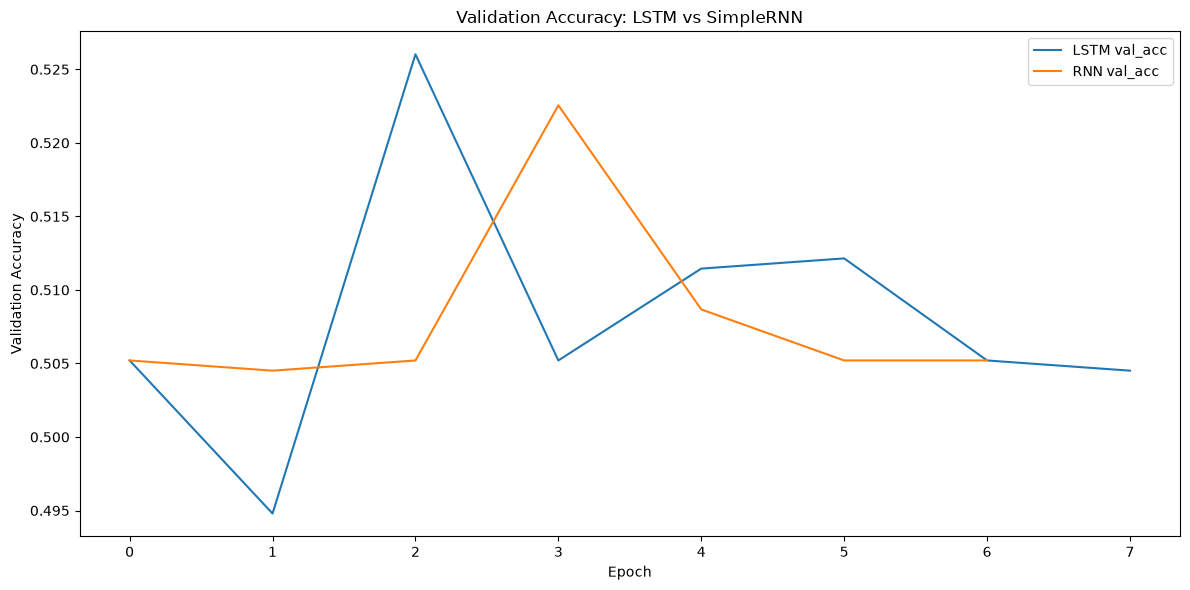

In [11]:
def plot_history(history_lstm, history_rnn):
    plt.figure(figsize=(12, 6))
    plt.plot(history_lstm.history['val_accuracy'], label='LSTM val_acc')
    plt.plot(history_rnn.history['val_accuracy'], label='RNN val_acc')
    plt.xlabel('Epoch')
    plt.ylabel('Validation Accuracy')
    plt.title('Validation Accuracy: LSTM vs SimpleRNN')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(history_lstm, history_rnn)

In [12]:
def evaluate_model(model, name):
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"{name} on test set")
    print(f"Test loss:     {loss:.4f}")
    print(f"Test accuracy: {acc:.4f}")

    y_prob = model.predict(x_test)
    y_pred = (y_prob > 0.5).astype(int).ravel()

    print("\nClassification report:")
    print(classification_report(y_test, y_pred, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    print("Confusion matrix:\n", cm)

    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d', cbar=False)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return acc, y_pred

LSTM on test set
Test loss:     0.6932
Test accuracy: 0.4997
 1/46 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step

16/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

31/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

45/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step



Classification report:
              precision    recall  f1-score   support

           0     0.4886    0.5170    0.5024       704
           1     0.5115    0.4830    0.4969       737

    accuracy                         0.4997      1441
   macro avg     0.5000    0.5000    0.4996      1441
weighted avg     0.5003    0.4997    0.4996      1441

Confusion matrix:
 [[364 340]
 [381 356]]


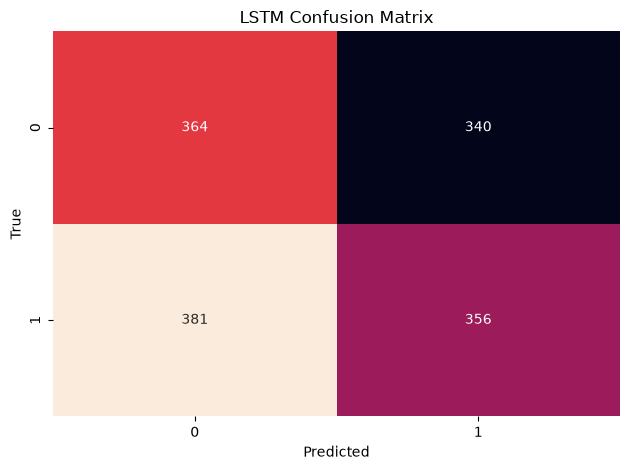

In [13]:
acc_lstm, y_pred_lstm = evaluate_model(model_lstm, 'LSTM')

SimpleRNN on test set


Test loss:     0.6933
Test accuracy: 0.4948


 1/46 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step

23/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step



Classification report:
              precision    recall  f1-score   support

           0     0.4828    0.4787    0.4807       704
           1     0.5061    0.5102    0.5081       737

    accuracy                         0.4948      1441
   macro avg     0.4944    0.4944    0.4944      1441
weighted avg     0.4947    0.4948    0.4947      1441

Confusion matrix:
 [[337 367]
 [361 376]]


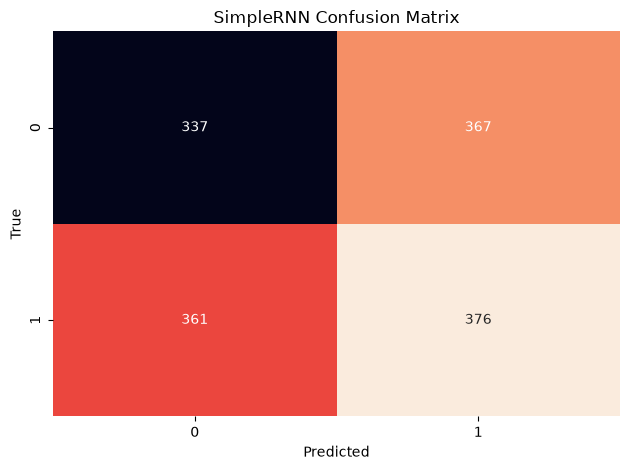

In [14]:
acc_rnn,  y_pred_rnn  = evaluate_model(model_rnn,  'SimpleRNN')

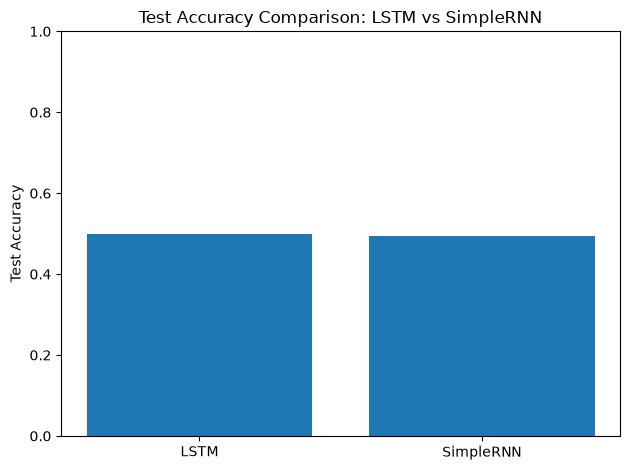

In [15]:
plt.figure()
models = ['LSTM', 'SimpleRNN']
accuracies = [acc_lstm, acc_rnn]
plt.bar(models, accuracies)
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy Comparison: LSTM vs SimpleRNN')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Analisis:
- Link dataset dari Kaggle: https://www.kaggle.com/datasets/mczielinski/bitcoin-historical-data
- Preprocessing: ubah timestamp, drop NaN value, hanya menggunakan 10.000 dataset.
- Implementasi LSTM dan RNN saya samakan agar perbandingannya adil, dengan layer model tersebut, dropout, dan dense, dengan optimizer yang sama juga.
- Grafik perbandingan antara kedua model hampir sama.

LSTM vs RNN:
- Kelebihan LSTM: parameternya lebih banyak dan lebih kompleks dibanding RNN, lebih stabil pada trend volatil
- Kekurangan LSTM: parameternya banyak jadi waktu untuk trainingnya jauh lebih lama daripada RNN
- Kelebihan RNN: arsitekturnya simple sehingga training lebih cepat daripada LSTM, juga konsumsi memorinya lebih kecil
- Kekurangan RNN: mudah terkena vanishing/exploding gradient, performa turun pada sequence panjang
- Dalam dataset ini, RNN lebih perform sedikit meskipun accuracy dari kedua model tersebut itu sama-sama 50:50 mungkin karena Bitcoin ini sangat volatil dan sangat susah untuk ditangkap polanya.